In [7]:

# CELL 1: KHAI BÁO THƯ VIỆN VÀ ĐỌC RAW DATA

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Đường dẫn chính xác của dự án
PROJECT_DIR = Path(r"C:\CreditAI_Project_Starter\CreditAI_Project")

# Các thư mục lưu trữ
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

# Tự động tạo thư mục nếu chưa có
for folder in [PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Đường dẫn dataset
DATA_PATH = RAW_DIR / "default of credit card clients.xls"

# Kiểm tra file
assert DATA_PATH.exists(), f"Không tìm thấy dataset: {DATA_PATH}"

# Đọc dữ liệu gốc
df = pd.read_excel(DATA_PATH, header=1)

print("ĐỌC DỮ LIỆU THÀNH CÔNG!")
print("Kích thước dữ liệu:", df.shape)
print("Số khách hàng:", df.shape[0])
print("Số cột:", df.shape[1])

display(df.head())


ĐỌC DỮ LIỆU THÀNH CÔNG!
Kích thước dữ liệu: (30000, 25)
Số khách hàng: 30000
Số cột: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [8]:

# ==================================================
# CELL 2: KIỂM TRA CẤU TRÚC VÀ CHẤT LƯỢNG RAW DATA
# ==================================================

# 1. Kiểm tra danh sách cột và kiểu dữ liệu
print("===== THÔNG TIN CẤU TRÚC DỮ LIỆU =====")
df.info()

# 2. Tạo bảng tổng hợp chất lượng từng cột
data_quality = pd.DataFrame({
    "Ten_cot": df.columns,
    "Kieu_du_lieu": df.dtypes.astype(str).values,
    "So_gia_tri_khong_thieu": df.notna().sum().values,
    "So_gia_tri_thieu": df.isna().sum().values,
    "Ty_le_thieu_%": (df.isna().mean() * 100).round(2).values,
    "So_gia_tri_phan_biet": df.nunique().values
})

print("\n===== BẢNG CHẤT LƯỢNG DỮ LIỆU =====")
display(data_quality)

# 3. Kiểm tra số dòng trùng hoàn toàn
print("\n===== KIỂM TRA TRÙNG LẶP =====")
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())
print("Số ID trùng:", df["ID"].duplicated().sum())

# 4. Kiểm tra mã giá trị của các biến phân loại
print("\n===== GIÁ TRỊ CÁC BIẾN PHÂN LOẠI =====")

for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).sort_index())

# 5. Kiểm tra biến mục tiêu
target_col = "default payment next month"

print("\n===== BIẾN MỤC TIÊU =====")
print(df[target_col].value_counts(dropna=False))

print("\nTỷ lệ phần trăm:")
print(
    (df[target_col].value_counts(normalize=True) * 100)
    .round(2)
)

# 6. Tự động lưu bảng kiểm tra
OUTPUT_PATH = REPORTS_DIR / "metrics"
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

data_quality.to_csv(
    OUTPUT_PATH / "01_data_quality.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu: reports/metrics/01_data_quality.csv")


===== THÔNG TIN CẤU TRÚC DỮ LIỆU =====
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000

,Ten_cot,Kieu_du_lieu,So_gia_tri_khong_thieu,So_gia_tri_thieu,Ty_le_thieu_%,So_gia_tri_phan_biet
0,ID,int64,30000,0,0.0,30000
1,LIMIT_BAL,int64,30000,0,0.0,81
2,SEX,int64,30000,0,0.0,2
3,EDUCATION,int64,30000,0,0.0,7
4,MARRIAGE,int64,30000,0,0.0,4
5,AGE,int64,30000,0,0.0,56
6,PAY_0,int64,30000,0,0.0,11
7,PAY_2,int64,30000,0,0.0,11
8,PAY_3,int64,30000,0,0.0,11
9,PAY_4,int64,30000,0,0.0,11



===== KIỂM TRA TRÙNG LẶP =====
Số dòng trùng hoàn toàn: 0
Số ID trùng: 0

===== GIÁ TRỊ CÁC BIẾN PHÂN LOẠI =====

SEX:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

===== BIẾN MỤC TIÊU =====
default payment next month
0    23364
1     6636
Name: count, dtype: int64

Tỷ lệ phần trăm:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

Đã lưu: reports/metrics/01_data_quality.csv


In [9]:

# =========================================================
# CELL 3: THỐNG KÊ MÔ TẢ VÀ KIỂM TRA GIÁ TRỊ BẤT THƯỜNG
# =========================================================

# 1. Thống kê mô tả các biến số
numeric_cols = (
    ["LIMIT_BAL", "AGE"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)

descriptive_stats = df[numeric_cols].describe().T.round(2)

print("===== THỐNG KÊ MÔ TẢ =====")
display(descriptive_stats)

# 2. Kiểm tra giá trị âm và bằng 0
value_checks = pd.DataFrame({
    "Ten_cot": numeric_cols,
    "So_gia_tri_am": [
        int((df[col] < 0).sum()) for col in numeric_cols
    ],
    "So_gia_tri_bang_0": [
        int((df[col] == 0).sum()) for col in numeric_cols
    ],
    "Gia_tri_nho_nhat": [
        df[col].min() for col in numeric_cols
    ],
    "Gia_tri_lon_nhat": [
        df[col].max() for col in numeric_cols
    ]
})

print("\n===== KIỂM TRA GIÁ TRỊ ÂM VÀ BẰNG 0 =====")
display(value_checks)

# 3. Kiểm tra các mã trạng thái trả nợ
pay_cols = ["PAY_0"] + [f"PAY_{i}" for i in range(2, 7)]

pay_distribution = pd.DataFrame({
    col: df[col].value_counts()
    for col in pay_cols
}).fillna(0).astype(int).sort_index()

pay_distribution.index.name = "Ma_trang_thai"

print("\n===== PHÂN BỐ MÃ LỊCH SỬ TRẢ NỢ =====")
display(pay_distribution)

# 4. Kiểm tra giá trị tuổi và hạn mức
print("\n===== KIỂM TRA GIÁ TRỊ CẦN LƯU Ý =====")
print("Tuổi dưới 18:", (df["AGE"] < 18).sum())
print("Tuổi trên 100:", (df["AGE"] > 100).sum())
print("Hạn mức <= 0:", (df["LIMIT_BAL"] <= 0).sum())

# 5. Tự động lưu kết quả
OUTPUT_PATH = REPORTS_DIR / "metrics"
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

descriptive_stats.to_csv(
    OUTPUT_PATH / "02_descriptive_statistics.csv",
    encoding="utf-8-sig"
)

value_checks.to_csv(
    OUTPUT_PATH / "03_value_checks.csv",
    index=False,
    encoding="utf-8-sig"
)

pay_distribution.to_csv(
    OUTPUT_PATH / "04_payment_status_distribution.csv",
    encoding="utf-8-sig"
)

print("\nĐÃ LƯU 3 BẢNG THỐNG KÊ VÀO reports/metrics/")


===== THỐNG KÊ MÔ TẢ =====


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0
BILL_AMT1,30000.0,51223.33,73635.86,-165580.0,3558.75,22381.5,67091.00,964511.0
BILL_AMT2,30000.0,49179.08,71173.77,-69777.0,2984.75,21200.0,64006.25,983931.0
BILL_AMT3,30000.0,47013.15,69349.39,-157264.0,2666.25,20088.5,60164.75,1664089.0
BILL_AMT4,30000.0,43262.95,64332.86,-170000.0,2326.75,19052.0,54506.00,891586.0
BILL_AMT5,30000.0,40311.40,60797.16,-81334.0,1763.00,18104.5,50190.50,927171.0
BILL_AMT6,30000.0,38871.76,59554.11,-339603.0,1256.00,17071.0,49198.25,961664.0
PAY_AMT1,30000.0,5663.58,16563.28,0.0,1000.00,2100.0,5006.00,873552.0
PAY_AMT2,30000.0,5921.16,23040.87,0.0,833.00,2009.0,5000.00,1684259.0



===== KIỂM TRA GIÁ TRỊ ÂM VÀ BẰNG 0 =====


,Ten_cot,So_gia_tri_am,So_gia_tri_bang_0,Gia_tri_nho_nhat,Gia_tri_lon_nhat
0,LIMIT_BAL,0,0,10000,1000000
1,AGE,0,0,21,79
2,BILL_AMT1,590,2008,-165580,964511
3,BILL_AMT2,669,2506,-69777,983931
4,BILL_AMT3,655,2870,-157264,1664089
5,BILL_AMT4,675,3195,-170000,891586
6,BILL_AMT5,655,3506,-81334,927171
7,BILL_AMT6,688,4020,-339603,961664
8,PAY_AMT1,0,5249,0,873552
9,PAY_AMT2,0,5396,0,1684259



===== PHÂN BỐ MÃ LỊCH SỬ TRẢ NỢ =====


,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
Ma_trang_thai,,,,,,
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19



===== KIỂM TRA GIÁ TRỊ CẦN LƯU Ý =====
Tuổi dưới 18: 0
Tuổi trên 100: 0
Hạn mức <= 0: 0

ĐÃ LƯU 3 BẢNG THỐNG KÊ VÀO reports/metrics/


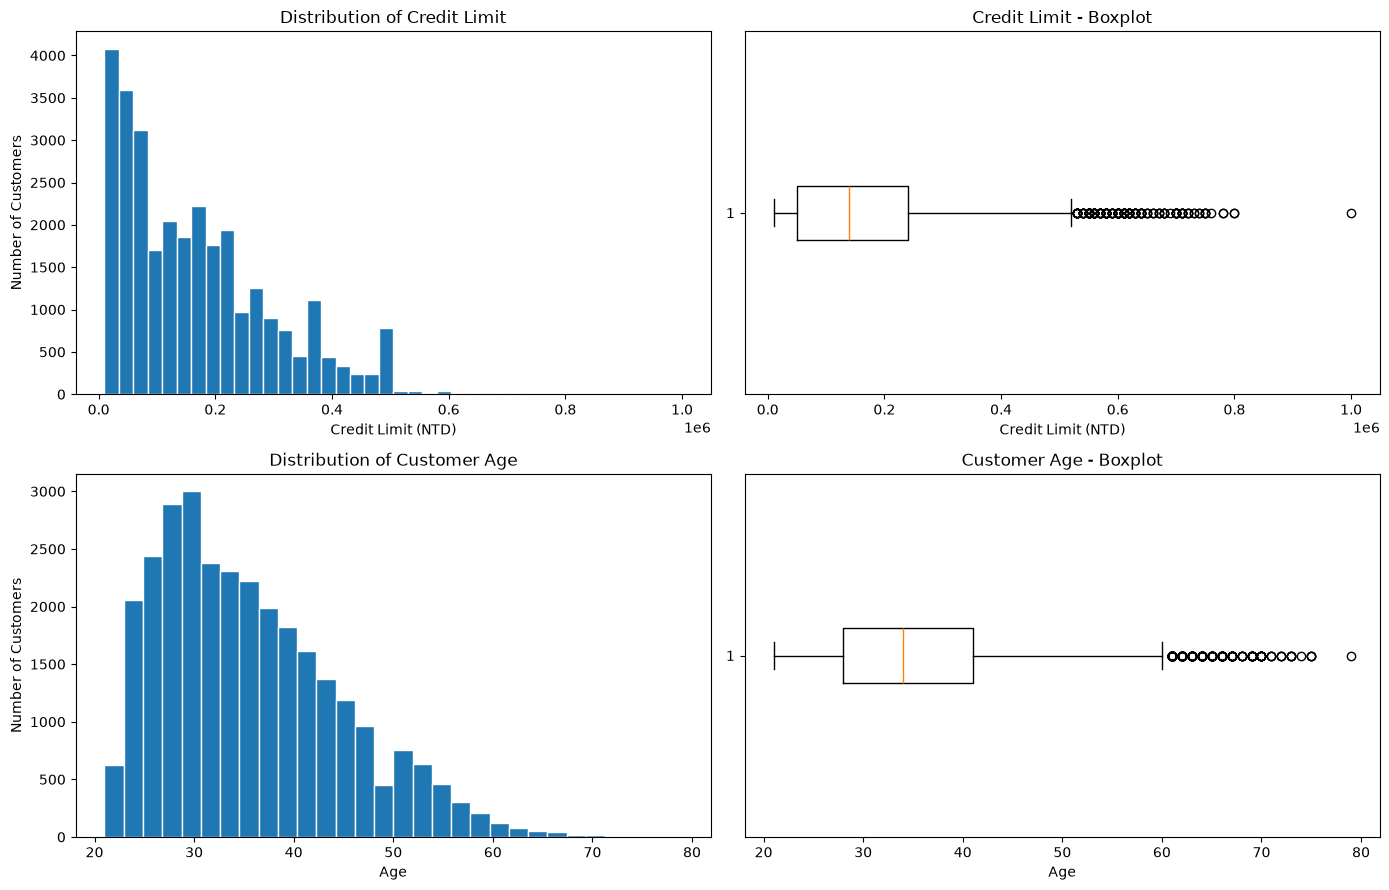

Đã lưu biểu đồ: C:\CreditAI_Project_Starter\CreditAI_Project\reports\figures\01_credit_limit_age_distribution.png


In [11]:

# =========================================================
# CELL 4: TRỰC QUAN HÓA HẠN MỨC TÍN DỤNG VÀ ĐỘ TUỔI
# =========================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Phân phối hạn mức tín dụng
axes[0, 0].hist(df["LIMIT_BAL"], bins=40, edgecolor="white")
axes[0, 0].set_title("Distribution of Credit Limit")
axes[0, 0].set_xlabel("Credit Limit (NTD)")
axes[0, 0].set_ylabel("Number of Customers")

# 2. Boxplot hạn mức tín dụng
axes[0, 1].boxplot(df["LIMIT_BAL"], orientation="horizontal")
axes[0, 1].set_title("Credit Limit - Boxplot")
axes[0, 1].set_xlabel("Credit Limit (NTD)")

# 3. Phân phối độ tuổi
axes[1, 0].hist(df["AGE"], bins=30, edgecolor="white")
axes[1, 0].set_title("Distribution of Customer Age")
axes[1, 0].set_xlabel("Age")
axes[1, 0].set_ylabel("Number of Customers")

# 4. Boxplot độ tuổi
axes[1, 1].boxplot(df["AGE"], orientation="horizontal")
axes[1, 1].set_title("Customer Age - Boxplot")
axes[1, 1].set_xlabel("Age")

plt.tight_layout()

# Lưu biểu đồ
figure_path = FIGURES_DIR / "01_credit_limit_age_distribution.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Đã lưu biểu đồ:", figure_path)


===== RỦI RO THEO HẠN MỨC TÍN DỤNG =====


,So_khach_hang,So_default,Ty_le_default
LIMIT_GROUP,,,
<=50K,7676,2440,31.79
50K-100K,4822,1244,25.80
100K-200K,7880,1535,19.48
200K-300K,5059,812,16.05
300K-500K,4357,582,13.36
>500K,206,23,11.17



===== RỦI RO THEO ĐỘ TUỔI =====


,So_khach_hang,So_default,Ty_le_default
AGE_GROUP,,,
<=25,3871,1032,26.66
26-35,12938,2565,19.83
36-45,8522,1861,21.84
46-55,3825,954,24.94
>55,844,224,26.54


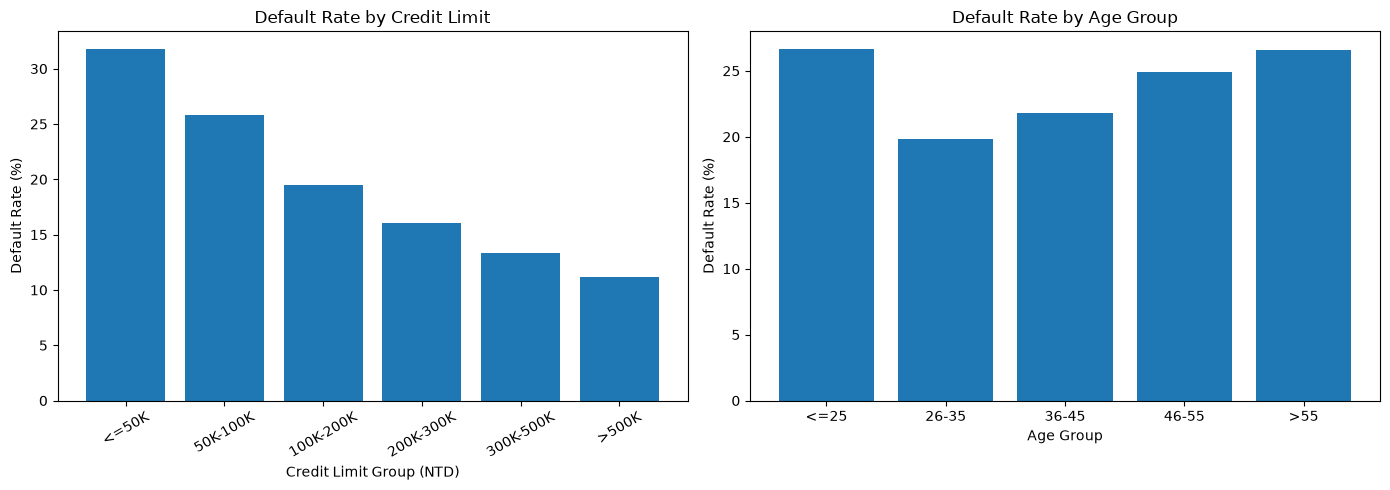


Đã lưu 2 bảng thống kê và 1 biểu đồ.


In [12]:

# =========================================================
# CELL 5: DEFAULT RATE THEO HẠN MỨC TÍN DỤNG VÀ ĐỘ TUỔI
# =========================================================

target_col = "default payment next month"

# Tạo bản sao để phân tích, không thay đổi dữ liệu gốc
eda_df = df.copy()

# Chia hạn mức tín dụng thành các nhóm
limit_bins = [0, 50000, 100000, 200000, 300000, 500000, float("inf")]
limit_labels = [
    "<=50K", "50K-100K", "100K-200K",
    "200K-300K", "300K-500K", ">500K"
]

eda_df["LIMIT_GROUP"] = pd.cut(
    eda_df["LIMIT_BAL"],
    bins=limit_bins,
    labels=limit_labels,
    include_lowest=True
)

# Chia độ tuổi thành các nhóm
age_bins = [0, 25, 35, 45, 55, float("inf")]
age_labels = ["<=25", "26-35", "36-45", "46-55", ">55"]

eda_df["AGE_GROUP"] = pd.cut(
    eda_df["AGE"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Tính tỷ lệ default theo từng nhóm
limit_risk = eda_df.groupby(
    "LIMIT_GROUP", observed=True
)[target_col].agg(
    So_khach_hang="count",
    So_default="sum",
    Ty_le_default="mean"
)

age_risk = eda_df.groupby(
    "AGE_GROUP", observed=True
)[target_col].agg(
    So_khach_hang="count",
    So_default="sum",
    Ty_le_default="mean"
)

limit_risk["Ty_le_default"] *= 100
age_risk["Ty_le_default"] *= 100

print("===== RỦI RO THEO HẠN MỨC TÍN DỤNG =====")
display(limit_risk.round(2))

print("\n===== RỦI RO THEO ĐỘ TUỔI =====")
display(age_risk.round(2))

# Vẽ hai biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    limit_risk.index.astype(str),
    limit_risk["Ty_le_default"]
)
axes[0].set_title("Default Rate by Credit Limit")
axes[0].set_xlabel("Credit Limit Group (NTD)")
axes[0].set_ylabel("Default Rate (%)")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(
    age_risk.index.astype(str),
    age_risk["Ty_le_default"]
)
axes[1].set_title("Default Rate by Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Default Rate (%)")

plt.tight_layout()

figure_path = FIGURES_DIR / "02_default_rate_by_limit_age.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# Lưu bảng thống kê
limit_risk.to_csv(
    OUTPUT_PATH / "05_default_by_limit.csv",
    encoding="utf-8-sig"
)

age_risk.to_csv(
    OUTPUT_PATH / "06_default_by_age.csv",
    encoding="utf-8-sig"
)

print("\nĐã lưu 2 bảng thống kê và 1 biểu đồ.")


===== DEFAULT THEO TRẠNG THÁI THÁNG GẦN NHẤT =====


,Ma_trang_thai,So_khach_hang,So_default,Ty_le_default,Thang
0,-2,2759,365,13.23,PAY_0
1,-1,5686,954,16.78,PAY_0
2,0,14737,1888,12.81,PAY_0
3,1,3688,1252,33.95,PAY_0
4,2,2667,1844,69.14,PAY_0
5,3,322,244,75.78,PAY_0
6,4,76,52,68.42,PAY_0
7,5,26,13,50.00,PAY_0
8,6,11,6,54.55,PAY_0
9,7,9,7,77.78,PAY_0



===== TỶ LỆ DEFAULT THEO MÃ VÀ THÁNG (%) =====


Thang,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
Ma_trang_thai,,,,,,
-2,13.23,18.27,18.53,19.25,19.69,20.04
-1,16.78,15.97,15.59,15.90,16.19,16.99
0,12.81,15.91,17.45,18.33,18.85,18.84
1,33.95,17.86,25.00,50.00,NaN,NaN
2,69.14,55.61,51.56,52.33,54.19,50.65
3,75.78,61.66,57.50,61.11,63.48,64.13
4,68.42,50.51,57.89,66.67,60.71,63.27
5,50.00,60.00,57.14,51.43,58.82,53.85
6,54.55,75.00,60.87,40.00,75.00,73.68


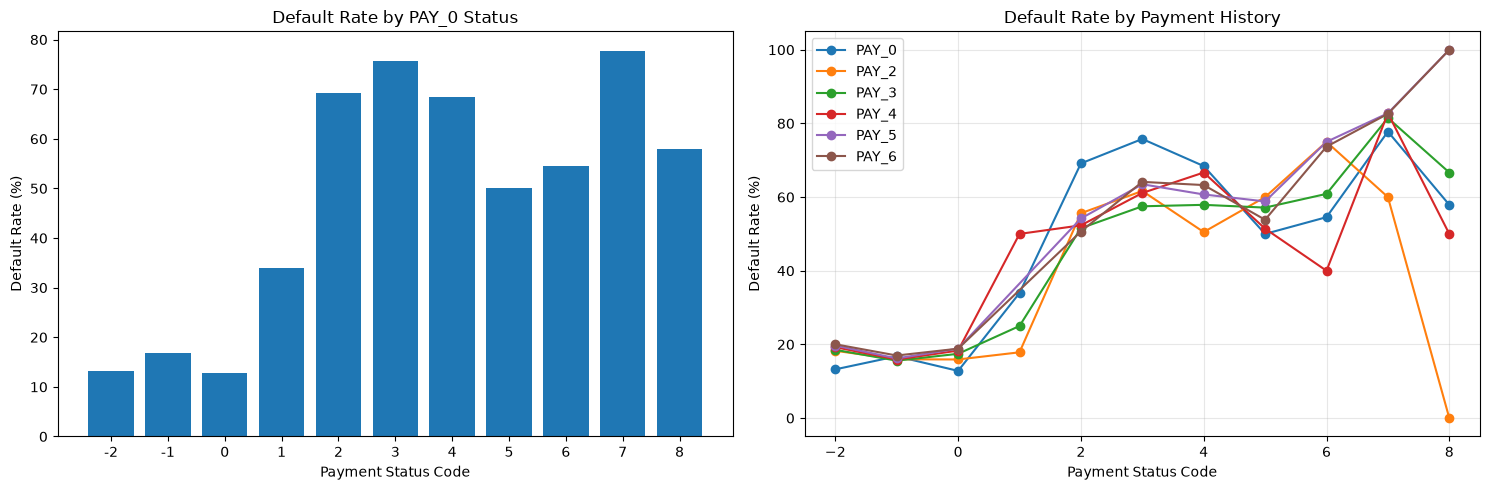


Đã lưu 2 bảng và 1 biểu đồ.


In [13]:

# =========================================================
# CELL 6: PHÂN TÍCH DEFAULT THEO LỊCH SỬ THANH TOÁN
# =========================================================

pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
target_col = "default payment next month"

# 1. Tính tỷ lệ default theo từng mã thanh toán, từng tháng
payment_risk_tables = []

for col in pay_cols:
    temp = df.groupby(col)[target_col].agg(
        So_khach_hang="count",
        So_default="sum",
        Ty_le_default="mean"
    ).reset_index()

    temp = temp.rename(columns={col: "Ma_trang_thai"})
    temp["Thang"] = col
    temp["Ty_le_default"] = temp["Ty_le_default"] * 100

    payment_risk_tables.append(temp)

payment_risk = pd.concat(
    payment_risk_tables, ignore_index=True
)

# 2. Hiển thị riêng tháng gần nhất
pay0_risk = payment_risk[
    payment_risk["Thang"] == "PAY_0"
].sort_values("Ma_trang_thai")

print("===== DEFAULT THEO TRẠNG THÁI THÁNG GẦN NHẤT =====")
display(pay0_risk.round(2))

# 3. Bảng tỷ lệ default cho cả 6 tháng
risk_pivot = payment_risk.pivot(
    index="Ma_trang_thai",
    columns="Thang",
    values="Ty_le_default"
)

print("\n===== TỶ LỆ DEFAULT THEO MÃ VÀ THÁNG (%) =====")
display(risk_pivot.round(2))

# 4. Biểu đồ tỷ lệ default tháng gần nhất
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
    pay0_risk["Ma_trang_thai"].astype(str),
    pay0_risk["Ty_le_default"]
)
axes[0].set_title("Default Rate by PAY_0 Status")
axes[0].set_xlabel("Payment Status Code")
axes[0].set_ylabel("Default Rate (%)")

# 5. Biểu đồ tỷ lệ default của tất cả các tháng
for col in pay_cols:
    subset = payment_risk[payment_risk["Thang"] == col]
    axes[1].plot(
        subset["Ma_trang_thai"],
        subset["Ty_le_default"],
        marker="o",
        label=col
    )

axes[1].set_title("Default Rate by Payment History")
axes[1].set_xlabel("Payment Status Code")
axes[1].set_ylabel("Default Rate (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

figure_path = FIGURES_DIR / "03_default_by_payment_history.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# 6. Lưu kết quả
payment_risk.to_csv(
    OUTPUT_PATH / "07_payment_history_default_rate.csv",
    index=False,
    encoding="utf-8-sig"
)

risk_pivot.to_csv(
    OUTPUT_PATH / "08_payment_history_risk_matrix.csv",
    encoding="utf-8-sig"
)

print("\nĐã lưu 2 bảng và 1 biểu đồ.")


===== DEFAULT THEO SỐ TIỀN SAO KÊ =====


,So_khach_hang,So_default,Ty_le_default
BILL_GROUP,,,
Negative,590,109,18.47
Zero,2008,534,26.59
0-10K,8257,1786,21.63
10K-50K,9639,2282,23.67
50K-100K,4600,968,21.04
>100K,4906,957,19.51



===== DEFAULT THEO SỐ TIỀN THANH TOÁN =====


,So_khach_hang,So_default,Ty_le_default
PAYMENT_GROUP,,,
Zero,5249,1887,35.95
0-1K,2590,597,23.05
1K-5K,14597,3112,21.32
5K-10K,4329,638,14.74
>10K,3235,402,12.43


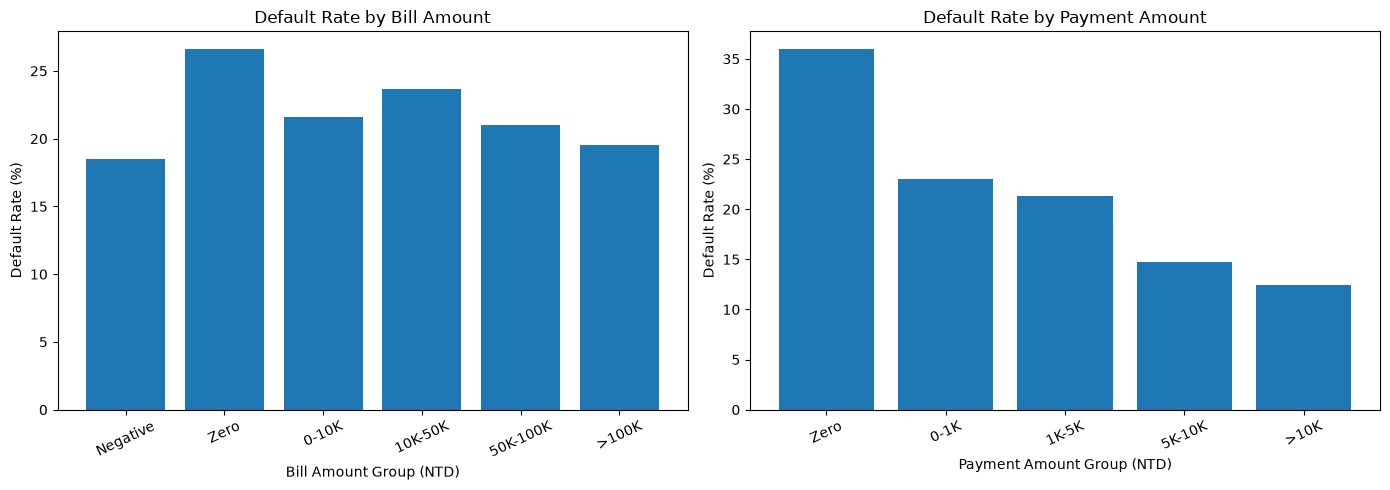


Đã lưu 2 bảng thống kê và 1 biểu đồ.


In [14]:

# =========================================================
# CELL 7: PHÂN TÍCH BILL_AMT VÀ PAY_AMT THEO DEFAULT
# =========================================================

target_col = "default payment next month"

bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

# Tạo bản sao, không thay đổi dữ liệu gốc
eda_financial = df.copy()

# 1. Phân nhóm số tiền sao kê tháng gần nhất
eda_financial["BILL_GROUP"] = pd.cut(
    eda_financial["BILL_AMT1"],
    bins=[-float("inf"), -0.001, 0, 10000,
          50000, 100000, float("inf")],
    labels=[
        "Negative", "Zero", "0-10K",
        "10K-50K", "50K-100K", ">100K"
    ]
)

# 2. Phân nhóm số tiền thanh toán tháng gần nhất
eda_financial["PAYMENT_GROUP"] = pd.cut(
    eda_financial["PAY_AMT1"],
    bins=[-0.001, 0, 1000, 5000, 10000, float("inf")],
    labels=[
        "Zero", "0-1K", "1K-5K",
        "5K-10K", ">10K"
    ]
)

# 3. Hàm thống kê tỷ lệ default
def calculate_risk(data, group_col):
    result = data.groupby(
        group_col, observed=True
    )[target_col].agg(
        So_khach_hang="count",
        So_default="sum",
        Ty_le_default="mean"
    )

    result["Ty_le_default"] *= 100
    return result.round(2)

bill_risk = calculate_risk(
    eda_financial, "BILL_GROUP"
)

payment_risk_financial = calculate_risk(
    eda_financial, "PAYMENT_GROUP"
)

print("===== DEFAULT THEO SỐ TIỀN SAO KÊ =====")
display(bill_risk)

print("\n===== DEFAULT THEO SỐ TIỀN THANH TOÁN =====")
display(payment_risk_financial)

# 4. Vẽ biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    bill_risk.index.astype(str),
    bill_risk["Ty_le_default"]
)
axes[0].set_title("Default Rate by Bill Amount")
axes[0].set_xlabel("Bill Amount Group (NTD)")
axes[0].set_ylabel("Default Rate (%)")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(
    payment_risk_financial.index.astype(str),
    payment_risk_financial["Ty_le_default"]
)
axes[1].set_title("Default Rate by Payment Amount")
axes[1].set_xlabel("Payment Amount Group (NTD)")
axes[1].set_ylabel("Default Rate (%)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()

figure_path = FIGURES_DIR / "04_default_by_financial_amount.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# 5. Lưu kết quả
bill_risk.to_csv(
    OUTPUT_PATH / "09_default_by_bill_amount.csv",
    encoding="utf-8-sig"
)

payment_risk_financial.to_csv(
    OUTPUT_PATH / "10_default_by_payment_amount.csv",
    encoding="utf-8-sig"
)

print("\nĐã lưu 2 bảng thống kê và 1 biểu đồ.")


===== DEFAULT THEO LỊCH SỬ VÀ THANH TOÁN =====


So_khach_hang  So_default  Ty_le_default
STATUS_GROUP      PAYMENT_ZERO                                          
Special (-2,-1,0) Payment = 0            2195         485          22.10
                  Payment > 0           20987        2722          12.97
Status 1          Payment = 0            2190         789          36.03
                  Payment > 0            1498         463          30.91
Status >=2        Payment = 0             864         613          70.95
                  Payment > 0            2266        1564          69.02


===== MA TRẬN TỶ LỆ DEFAULT (%) =====


PAYMENT_ZERO,Payment = 0,Payment > 0
STATUS_GROUP,,
"Special (-2,-1,0)",22.10,12.97
Status 1,36.03,30.91
Status >=2,70.95,69.02



===== MA TRẬN SỐ KHÁCH HÀNG =====


PAYMENT_ZERO,Payment = 0,Payment > 0
STATUS_GROUP,,
"Special (-2,-1,0)",2195,20987
Status 1,2190,1498
Status >=2,864,2266


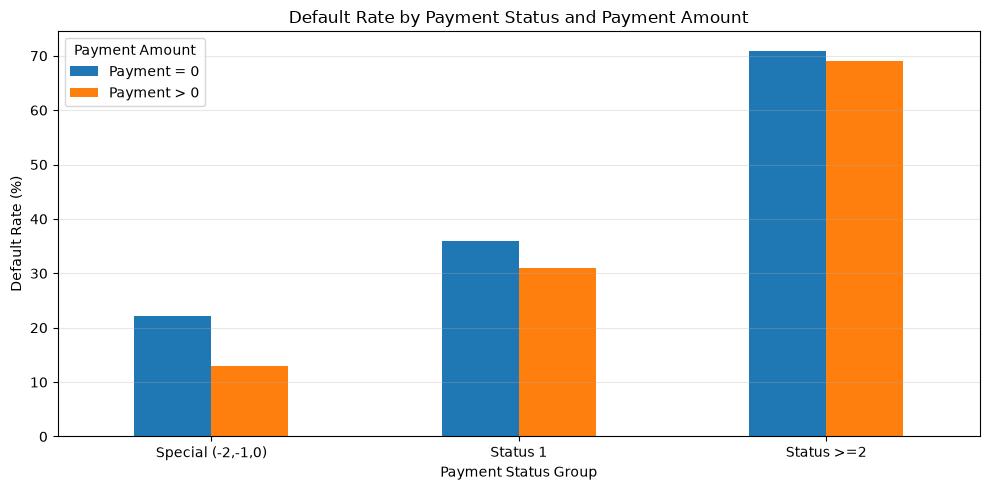


Đã lưu 2 bảng thống kê và 1 biểu đồ.


In [15]:

# =========================================================
# CELL 8: KẾT HỢP LỊCH SỬ VÀ SỐ TIỀN THANH TOÁN
# =========================================================

target_col = "default payment next month"

# Tạo bản sao, không thay đổi dữ liệu gốc
eda_combined = df.copy()

# 1. Phân nhóm trạng thái thanh toán gần nhất
def classify_payment_status(value):
    if value in [-2, -1, 0]:
        return "Special (-2,-1,0)"
    elif value == 1:
        return "Status 1"
    else:
        return "Status >=2"

eda_combined["STATUS_GROUP"] = (
    eda_combined["PAY_0"].apply(classify_payment_status)
)

# 2. Phân nhóm có hoặc không ghi nhận thanh toán
eda_combined["PAYMENT_ZERO"] = np.where(
    eda_combined["PAY_AMT1"] == 0,
    "Payment = 0",
    "Payment > 0"
)

# 3. Thống kê theo kết hợp hai nhóm
combined_risk = eda_combined.groupby(
    ["STATUS_GROUP", "PAYMENT_ZERO"]
)[target_col].agg(
    So_khach_hang="count",
    So_default="sum",
    Ty_le_default="mean"
)

combined_risk["Ty_le_default"] *= 100

print("===== DEFAULT THEO LỊCH SỬ VÀ THANH TOÁN =====")
display(combined_risk.round(2))

# 4. Tạo ma trận tỷ lệ default
risk_matrix = combined_risk[
    "Ty_le_default"
].unstack()

count_matrix = combined_risk[
    "So_khach_hang"
].unstack()

print("\n===== MA TRẬN TỶ LỆ DEFAULT (%) =====")
display(risk_matrix.round(2))

print("\n===== MA TRẬN SỐ KHÁCH HÀNG =====")
display(count_matrix)

# 5. Vẽ biểu đồ so sánh
ax = risk_matrix.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Default Rate by Payment Status and Payment Amount")
ax.set_xlabel("Payment Status Group")
ax.set_ylabel("Default Rate (%)")
ax.legend(title="Payment Amount")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

figure_path = FIGURES_DIR / "05_combined_payment_risk.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# 6. Lưu bảng kết quả
combined_risk.to_csv(
    OUTPUT_PATH / "11_combined_payment_risk.csv",
    encoding="utf-8-sig"
)

risk_matrix.to_csv(
    OUTPUT_PATH / "12_combined_risk_matrix.csv",
    encoding="utf-8-sig"
)

print("\nĐã lưu 2 bảng thống kê và 1 biểu đồ.")


===== DEFAULT THEO SỐ KỲ CHẬM THANH TOÁN =====


,So_khach_hang,So_default,Ty_le_default
DELAY_COUNT,,,
0,19931,2334,11.71
1,4426,1320,29.82
2,1899,736,38.76
3,1154,587,50.87
4,951,545,57.31
5,298,171,57.38
6,1341,943,70.32



===== DEFAULT THEO SỐ KỲ CHẬM TỪ 2 TRỞ LÊN =====


,So_khach_hang,So_default,Ty_le_default
SEVERE_DELAY_COUNT,,,
0,21620,2756,12.75
1,3494,1126,32.23
2,1567,680,43.40
3,1073,588,54.80
4,711,419,58.93
5,597,341,57.12
6,938,726,77.40



===== DEFAULT THEO SỐ THÁNG THANH TOÁN BẰNG 0 =====


,So_khach_hang,So_default,Ty_le_default
ZERO_PAYMENT_COUNT,,,
0,15458,2151,13.92
1,5473,1586,28.98
2,3387,1141,33.69
3,1944,608,31.28
4,1304,328,25.15
5,1002,278,27.74
6,1432,544,37.99


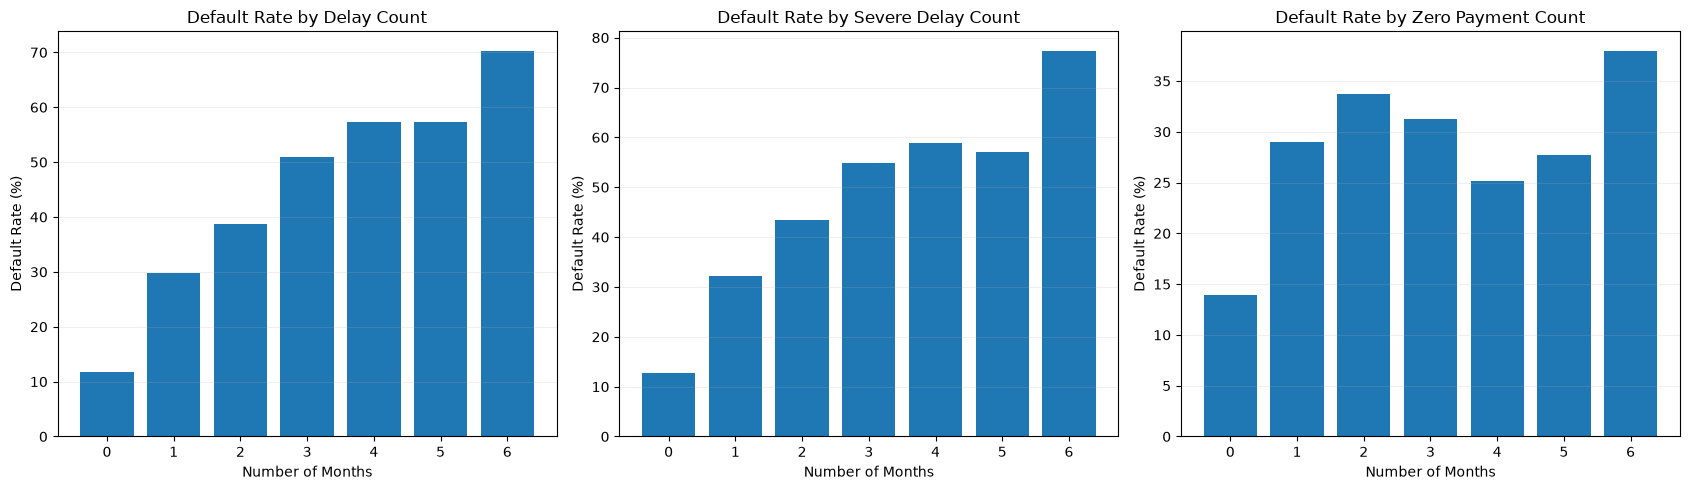


Đã lưu 3 bảng và 1 hình biểu đồ.


In [16]:

# =========================================================
# CELL 9: PHÂN TÍCH HÀNH VI THANH TOÁN TRONG 6 THÁNG
# =========================================================

target_col = "default payment next month"

status_cols = ["PAY_0", "PAY_2", "PAY_3",
               "PAY_4", "PAY_5", "PAY_6"]

amount_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

# 1. Tạo bản sao dữ liệu
eda_behavior = df.copy()

# Số kỳ có mã chậm thanh toán dương
eda_behavior["DELAY_COUNT"] = (
    eda_behavior[status_cols] > 0
).sum(axis=1)

# Số kỳ có mã chậm thanh toán từ 2 trở lên
eda_behavior["SEVERE_DELAY_COUNT"] = (
    eda_behavior[status_cols] >= 2
).sum(axis=1)

# Số tháng có khoản thanh toán bằng 0
eda_behavior["ZERO_PAYMENT_COUNT"] = (
    eda_behavior[amount_cols] == 0
).sum(axis=1)

# Tổng số tiền đã thanh toán trong 6 tháng
eda_behavior["TOTAL_PAYMENT_6M"] = (
    eda_behavior[amount_cols].sum(axis=1)
)

# 2. Hàm tính tỷ lệ default
def behavior_risk_table(column):
    result = eda_behavior.groupby(column)[target_col].agg(
        So_khach_hang="count",
        So_default="sum",
        Ty_le_default="mean"
    )
    result["Ty_le_default"] *= 100
    return result.round(2)

delay_risk = behavior_risk_table("DELAY_COUNT")
severe_risk = behavior_risk_table("SEVERE_DELAY_COUNT")
zero_risk = behavior_risk_table("ZERO_PAYMENT_COUNT")

print("===== DEFAULT THEO SỐ KỲ CHẬM THANH TOÁN =====")
display(delay_risk)

print("\n===== DEFAULT THEO SỐ KỲ CHẬM TỪ 2 TRỞ LÊN =====")
display(severe_risk)

print("\n===== DEFAULT THEO SỐ THÁNG THANH TOÁN BẰNG 0 =====")
display(zero_risk)

# 3. Trực quan hóa
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

tables = [delay_risk, severe_risk, zero_risk]
titles = [
    "Default Rate by Delay Count",
    "Default Rate by Severe Delay Count",
    "Default Rate by Zero Payment Count"
]

for ax, table, title in zip(axes, tables, titles):
    ax.bar(
        table.index,
        table["Ty_le_default"]
    )
    ax.set_title(title)
    ax.set_xlabel("Number of Months")
    ax.set_ylabel("Default Rate (%)")
    ax.set_xticks(range(7))
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

figure_path = FIGURES_DIR / "06_six_month_payment_behavior.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# 4. Lưu kết quả
delay_risk.to_csv(
    OUTPUT_PATH / "13_default_by_delay_count.csv",
    encoding="utf-8-sig"
)

severe_risk.to_csv(
    OUTPUT_PATH / "14_default_by_severe_delay.csv",
    encoding="utf-8-sig"
)

zero_risk.to_csv(
    OUTPUT_PATH / "15_default_by_zero_payment_count.csv",
    encoding="utf-8-sig"
)

print("\nĐã lưu 3 bảng và 1 hình biểu đồ.")


===== DEFAULT THEO TỶ LỆ SAO KÊ / HẠN MỨC =====


,So_khach_hang,So_default,Ty_le_default
UTIL_GROUP,,,
Negative,590,109,18.47
Zero,2008,534,26.59
0-25%,11440,1923,16.81
25-50%,3588,780,21.74
50-75%,3579,929,25.96
75-100%,6680,1725,25.82
>100%,2115,636,30.07



===== KIỂM TRA TỶ LỆ SỬ DỤNG =====
Số khách hàng có tỷ lệ âm: 590
Số khách hàng có tỷ lệ > 100%: 2115
Tỷ lệ lớn nhất: 6.4553


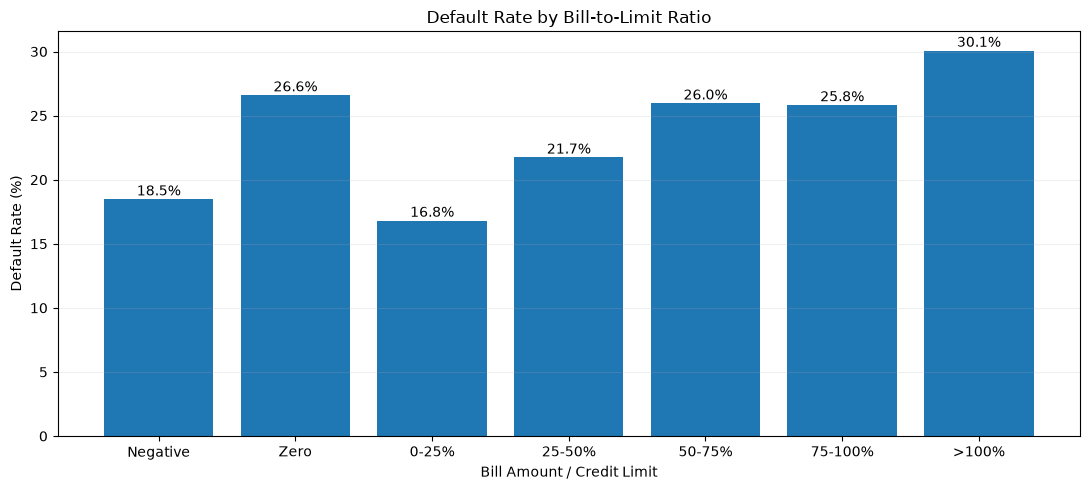


Đã lưu bảng và biểu đồ Cell 10.


In [17]:

# =========================================================
# CELL 10: PHÂN TÍCH TỶ LỆ SAO KÊ / HẠN MỨC
# =========================================================

target_col = "default payment next month"

# 1. Tạo bản sao dữ liệu
eda_util = df.copy()

# 2. Tính tỷ lệ sao kê so với hạn mức
eda_util["UTILIZATION_RATIO"] = (
    eda_util["BILL_AMT1"] / eda_util["LIMIT_BAL"]
)

# 3. Phân nhóm tỷ lệ
util_bins = [
    -float("inf"), -0.000001, 0,
    0.25, 0.50, 0.75, 1.00, float("inf")
]

util_labels = [
    "Negative", "Zero", "0-25%",
    "25-50%", "50-75%", "75-100%", ">100%"
]

eda_util["UTIL_GROUP"] = pd.cut(
    eda_util["UTILIZATION_RATIO"],
    bins=util_bins,
    labels=util_labels,
    include_lowest=True
)

# 4. Tính tỷ lệ default
util_risk = eda_util.groupby(
    "UTIL_GROUP", observed=True
)[target_col].agg(
    So_khach_hang="count",
    So_default="sum",
    Ty_le_default="mean"
)

util_risk["Ty_le_default"] *= 100

print("===== DEFAULT THEO TỶ LỆ SAO KÊ / HẠN MỨC =====")
display(util_risk.round(2))

# 5. Kiểm tra các trường hợp đặc biệt
print("\n===== KIỂM TRA TỶ LỆ SỬ DỤNG =====")
print(
    "Số khách hàng có tỷ lệ âm:",
    (eda_util["UTILIZATION_RATIO"] < 0).sum()
)
print(
    "Số khách hàng có tỷ lệ > 100%:",
    (eda_util["UTILIZATION_RATIO"] > 1).sum()
)
print(
    "Tỷ lệ lớn nhất:",
    round(eda_util["UTILIZATION_RATIO"].max(), 4)
)

# 6. Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    util_risk.index.astype(str),
    util_risk["Ty_le_default"]
)

ax.set_title("Default Rate by Bill-to-Limit Ratio")
ax.set_xlabel("Bill Amount / Credit Limit")
ax.set_ylabel("Default Rate (%)")
ax.grid(axis="y", alpha=0.2)

for bar, value in zip(bars, util_risk["Ty_le_default"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()

figure_path = FIGURES_DIR / "07_default_by_utilization.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# 7. Lưu kết quả
util_risk.to_csv(
    OUTPUT_PATH / "16_default_by_utilization.csv",
    encoding="utf-8-sig"
)

print("\nĐã lưu bảng và biểu đồ Cell 10.")



===== DEFAULT THEO SEX =====


,So_khach_hang,So_default,Ty_le_default
SEX,,,
1,11888,2873,24.17
2,18112,3763,20.78



===== DEFAULT THEO EDUCATION =====


,So_khach_hang,So_default,Ty_le_default
EDUCATION,,,
0,14,0,0.00
1,10585,2036,19.23
2,14030,3330,23.73
3,4917,1237,25.16
4,123,7,5.69
5,280,18,6.43
6,51,8,15.69



===== DEFAULT THEO MARRIAGE =====


,So_khach_hang,So_default,Ty_le_default
MARRIAGE,,,
0,54,5,9.26
1,13659,3206,23.47
2,15964,3341,20.93
3,323,84,26.01


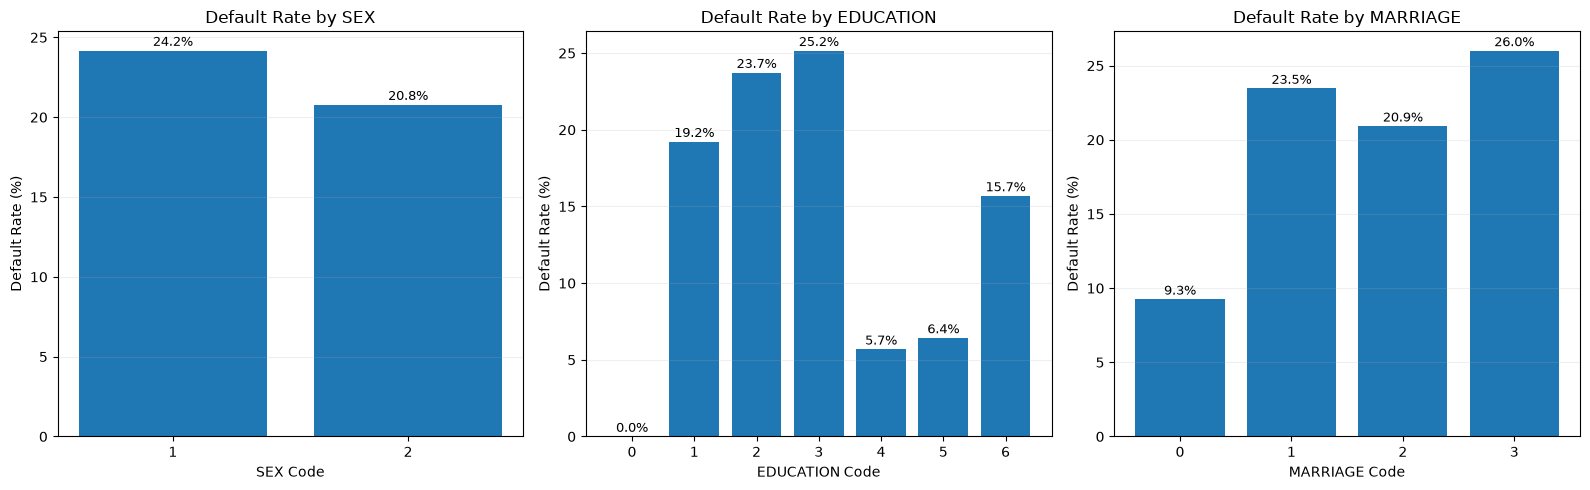


Đã lưu 3 bảng và 1 biểu đồ Cell 11.


In [18]:

# =========================================================
# CELL 11: PHÂN TÍCH BIẾN PHÂN LOẠI VÀ DEFAULT
# =========================================================

target_col = "default payment next month"
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE"]

# 1. Tạo bản sao, giữ nguyên dữ liệu gốc
eda_categorical = df.copy()

# 2. Hàm thống kê theo từng mã phân loại
def categorical_risk_table(col):
    result = eda_categorical.groupby(col)[target_col].agg(
        So_khach_hang="count",
        So_default="sum",
        Ty_le_default="mean"
    )

    result["Ty_le_default"] *= 100
    return result.round(2)

risk_tables = {}

for col in categorical_cols:
    risk_tables[col] = categorical_risk_table(col)

    print(f"\n===== DEFAULT THEO {col} =====")
    display(risk_tables[col])

# 3. Vẽ 3 biểu đồ
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, categorical_cols):
    table = risk_tables[col]

    bars = ax.bar(
        table.index.astype(str),
        table["Ty_le_default"]
    )

    ax.set_title(f"Default Rate by {col}")
    ax.set_xlabel(f"{col} Code")
    ax.set_ylabel("Default Rate (%)")
    ax.grid(axis="y", alpha=0.2)

    for bar, rate in zip(bars, table["Ty_le_default"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            f"{rate:.1f}%",
            ha="center",
            fontsize=9
        )

plt.tight_layout()

figure_path = FIGURES_DIR / "08_default_by_categorical_features.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# 4. Lưu bảng kết quả
for col, table in risk_tables.items():
    table.to_csv(
        OUTPUT_PATH / f"17_default_by_{col.lower()}.csv",
        encoding="utf-8-sig"
    )

print("\nĐã lưu 3 bảng và 1 biểu đồ Cell 11.")


===== MA TRẬN TƯƠNG QUAN PEARSON =====


,LIMIT_BAL,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
LIMIT_BAL,1.00,-0.27,-0.30,-0.29,-0.27,-0.25,-0.24,0.29,0.28,0.28,0.29,0.30,0.29,0.20,0.18,0.21,0.20,0.22,0.22,-0.15
PAY_0,-0.27,1.00,0.67,0.57,0.54,0.51,0.47,0.19,0.19,0.18,0.18,0.18,0.18,-0.08,-0.07,-0.07,-0.06,-0.06,-0.06,0.32
PAY_2,-0.30,0.67,1.00,0.77,0.66,0.62,0.58,0.23,0.24,0.22,0.22,0.22,0.22,-0.08,-0.06,-0.06,-0.05,-0.04,-0.04,0.26
PAY_3,-0.29,0.57,0.77,1.00,0.78,0.69,0.63,0.21,0.24,0.23,0.23,0.23,0.22,0.00,-0.07,-0.05,-0.05,-0.04,-0.04,0.24
PAY_4,-0.27,0.54,0.66,0.78,1.00,0.82,0.72,0.20,0.23,0.24,0.25,0.24,0.24,-0.01,-0.00,-0.07,-0.04,-0.03,-0.03,0.22
PAY_5,-0.25,0.51,0.62,0.69,0.82,1.00,0.82,0.21,0.23,0.24,0.27,0.27,0.26,-0.01,-0.00,0.01,-0.06,-0.03,-0.02,0.20
PAY_6,-0.24,0.47,0.58,0.63,0.72,0.82,1.00,0.21,0.23,0.24,0.27,0.29,0.29,-0.00,-0.01,0.01,0.02,-0.05,-0.03,0.19
BILL_AMT1,0.29,0.19,0.23,0.21,0.20,0.21,0.21,1.00,0.95,0.89,0.86,0.83,0.80,0.14,0.10,0.16,0.16,0.17,0.18,-0.02
BILL_AMT2,0.28,0.19,0.24,0.24,0.23,0.23,0.23,0.95,1.00,0.93,0.89,0.86,0.83,0.28,0.10,0.15,0.15,0.16,0.17,-0.01
BILL_AMT3,0.28,0.18,0.22,0.23,0.24,0.24,0.24,0.89,0.93,1.00,0.92,0.88,0.85,0.24,0.32,0.13,0.14,0.18,0.18,-0.01



===== CÁC CẶP TƯƠNG QUAN MẠNH (|r| >= 0.8) =====


,Bien_1,Bien_2,He_so_tuong_quan,Do_manh
141,BILL_AMT1,BILL_AMT2,0.9515,0.9515
221,BILL_AMT5,BILL_AMT6,0.9462,0.9462
201,BILL_AMT4,BILL_AMT5,0.9401,0.9401
161,BILL_AMT2,BILL_AMT3,0.9283,0.9283
181,BILL_AMT3,BILL_AMT4,0.9240,0.9240
202,BILL_AMT4,BILL_AMT6,0.9009,0.9009
162,BILL_AMT2,BILL_AMT4,0.8925,0.8925
142,BILL_AMT1,BILL_AMT3,0.8923,0.8923
182,BILL_AMT3,BILL_AMT5,0.8839,0.8839
143,BILL_AMT1,BILL_AMT4,0.8603,0.8603



===== TƯƠNG QUAN VỚI BIẾN MỤC TIÊU =====


,Tuong_quan_voi_default
PAY_0,0.3248
PAY_2,0.2636
PAY_3,0.2353
PAY_4,0.2166
PAY_5,0.2041
PAY_6,0.1869
LIMIT_BAL,-0.1535
PAY_AMT1,-0.0729
PAY_AMT2,-0.0586
PAY_AMT4,-0.0568


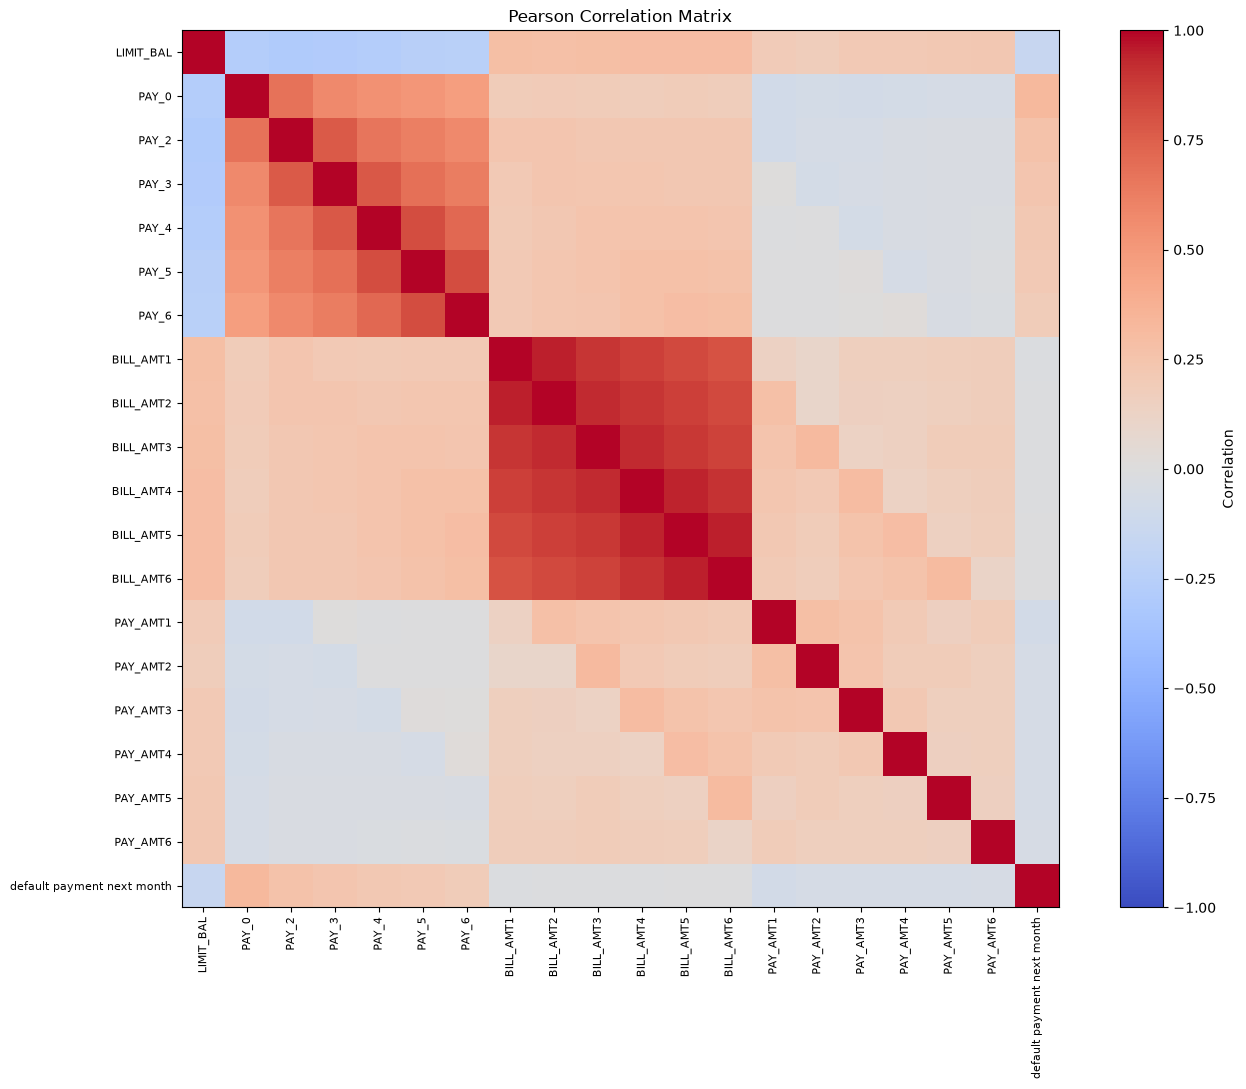


Đã lưu 3 bảng và 1 biểu đồ Cell 12.


In [19]:

# =========================================================
# CELL 12: PHÂN TÍCH TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

target_col = "default payment next month"

# 1. Chọn các đặc trưng tài chính và hành vi
feature_cols = (
    ["LIMIT_BAL"]
    + ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)

# Không đưa ID và các biến nhân khẩu học vào ma trận
corr_df = df[feature_cols + [target_col]].copy()

# 2. Tính ma trận tương quan Pearson
corr_matrix = corr_df.corr(method="pearson")

print("===== MA TRẬN TƯƠNG QUAN PEARSON =====")
display(corr_matrix.round(2))

# 3. Tìm các cặp đặc trưng tương quan mạnh
feature_corr = corr_matrix.loc[feature_cols, feature_cols]

upper_mask = np.triu(
    np.ones(feature_corr.shape, dtype=bool),
    k=1
)

strong_pairs = (
    feature_corr.where(upper_mask)
    .stack()
    .reset_index()
)

strong_pairs.columns = [
    "Bien_1", "Bien_2", "He_so_tuong_quan"
]

strong_pairs["Do_manh"] = (
    strong_pairs["He_so_tuong_quan"].abs()
)

strong_pairs = strong_pairs[
    strong_pairs["Do_manh"] >= 0.8
].sort_values("Do_manh", ascending=False)

print("\n===== CÁC CẶP TƯƠNG QUAN MẠNH (|r| >= 0.8) =====")
display(strong_pairs.round(4))

# 4. Tương quan với biến mục tiêu
target_corr = (
    corr_matrix[target_col]
    .drop(target_col)
    .sort_values(key=abs, ascending=False)
    .to_frame("Tuong_quan_voi_default")
)

print("\n===== TƯƠNG QUAN VỚI BIẾN MỤC TIÊU =====")
display(target_corr.round(4))

# 5. Vẽ heatmap bằng Matplotlib
fig, ax = plt.subplots(figsize=(14, 11))

im = ax.imshow(
    corr_matrix.values,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))

ax.set_xticklabels(
    corr_matrix.columns,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    corr_matrix.columns,
    fontsize=8
)

ax.set_title("Pearson Correlation Matrix")

fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()

figure_path = FIGURES_DIR / "09_correlation_heatmap.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# 6. Lưu các bảng
corr_matrix.to_csv(
    OUTPUT_PATH / "18_correlation_matrix.csv",
    encoding="utf-8-sig"
)

strong_pairs.to_csv(
    OUTPUT_PATH / "19_strong_correlation_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

target_corr.to_csv(
    OUTPUT_PATH / "20_target_correlations.csv",
    encoding="utf-8-sig"
)

print("\nĐã lưu 3 bảng và 1 biểu đồ Cell 12.")


In [20]:

# =========================================================
# CELL 13: TỔNG KIỂM TRA VÀ KẾT THÚC EDA
# =========================================================

target_col = "default payment next month"

# 1. Kiểm tra dữ liệu gốc
print("===== TỔNG QUAN DỮ LIỆU =====")
print("Số dòng:", len(df))
print("Số cột:", len(df.columns))
print("Số giá trị thiếu:", int(df.isna().sum().sum()))
print("Số dòng trùng:", int(df.duplicated().sum()))
print("Số ID trùng:", int(df["ID"].duplicated().sum()))
print("Tỷ lệ default (%):", round(df[target_col].mean() * 100, 2))

# 2. Tổng hợp vấn đề cần xử lý
eda_issues = pd.DataFrame([
    {
        "Nhom_bien": "ID",
        "Van_de": "Mã định danh khách hàng",
        "Huong_xu_ly": "Loại khỏi tập đặc trưng đầu vào"
    },
    {
        "Nhom_bien": "EDUCATION",
        "Van_de": "Mã 0, 5, 6 chưa được định nghĩa",
        "Huong_xu_ly": "Chuẩn hóa thành Unknown khi phân tích"
    },
    {
        "Nhom_bien": "MARRIAGE",
        "Van_de": "Mã 0 chưa được định nghĩa",
        "Huong_xu_ly": "Chuẩn hóa thành Unknown khi phân tích"
    },
    {
        "Nhom_bien": "SEX, EDUCATION, MARRIAGE, AGE",
        "Van_de": "Đặc trưng nhân khẩu học",
        "Huong_xu_ly": "Đánh giá công bằng; không dùng trong mô hình chính"
    },
    {
        "Nhom_bien": "PAY_0 - PAY_6",
        "Van_de": "Mã đặc biệt -2, -1, 0",
        "Huong_xu_ly": "Giữ mã gốc, thử đặc trưng lịch sử"
    },
    {
        "Nhom_bien": "BILL_AMT1 - BILL_AMT6",
        "Van_de": "Giá trị âm, bằng 0, cực trị và tương quan cao",
        "Huong_xu_ly": "Không xóa tự động; thử đặc trưng tổng hợp"
    },
    {
        "Nhom_bien": "PAY_AMT1 - PAY_AMT6",
        "Van_de": "Nhiều khoản thanh toán bằng 0 và cực trị",
        "Huong_xu_ly": "Giữ lại; thử biến chỉ báo và tổng hợp"
    },
    {
        "Nhom_bien": target_col,
        "Van_de": "Tỷ lệ default 22.12%",
        "Huong_xu_ly": "Chia tập phân tầng; dùng PR-AUC, ROC-AUC, Recall, F1"
    }
])

print("\n===== DANH SÁCH VẤN ĐỀ TIỀN XỬ LÝ =====")
display(eda_issues)

# 3. Kiểm tra các file kết quả đã lưu
metrics_files = sorted(OUTPUT_PATH.glob("*.csv"))
figure_files = sorted(FIGURES_DIR.glob("*.png"))

print("\n===== FILE KẾT QUẢ EDA =====")
print("Số file CSV:", len(metrics_files))
print("Số file biểu đồ PNG:", len(figure_files))

# 4. Lưu bảng tổng hợp
summary_path = OUTPUT_PATH / "21_eda_issues_summary.csv"
eda_issues.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu:", summary_path)
print("CELL 13 HOÀN THÀNH!")


===== TỔNG QUAN DỮ LIỆU =====
Số dòng: 30000
Số cột: 25
Số giá trị thiếu: 0
Số dòng trùng: 0
Số ID trùng: 0
Tỷ lệ default (%): 22.12

===== DANH SÁCH VẤN ĐỀ TIỀN XỬ LÝ =====


,Nhom_bien,Van_de,Huong_xu_ly
0,ID,Mã định danh khách hàng,Loại khỏi tập đặc trưng đầu vào
1,EDUCATION,"Mã 0, 5, 6 chưa được định nghĩa",Chuẩn hóa thành Unknown khi phân tích
2,MARRIAGE,Mã 0 chưa được định nghĩa,Chuẩn hóa thành Unknown khi phân tích
3,"SEX, EDUCATION, MARRIAGE, AGE",Đặc trưng nhân khẩu học,Đánh giá công bằng; không dùng trong mô hình c...
4,PAY_0 - PAY_6,"Mã đặc biệt -2, -1, 0","Giữ mã gốc, thử đặc trưng lịch sử"
5,BILL_AMT1 - BILL_AMT6,"Giá trị âm, bằng 0, cực trị và tương quan cao",Không xóa tự động; thử đặc trưng tổng hợp
6,PAY_AMT1 - PAY_AMT6,Nhiều khoản thanh toán bằng 0 và cực trị,Giữ lại; thử biến chỉ báo và tổng hợp
7,default payment next month,Tỷ lệ default 22.12%,"Chia tập phân tầng; dùng PR-AUC, ROC-AUC, Reca..."



===== FILE KẾT QUẢ EDA =====
Số file CSV: 22
Số file biểu đồ PNG: 9

Đã lưu: C:\CreditAI_Project_Starter\CreditAI_Project\reports\metrics\21_eda_issues_summary.csv
CELL 13 HOÀN THÀNH!
